# Gini trajectory diagnostic across τ conditions

**Purpose.** Before calibrating the deprivation-sensitivity parameter λ, check whether the model
produces *enough inequality variation to identify a slope* — either over time (within a run) or
across the τ conditions. If the Gini is near-saturated from initialization and barely moves, a
temporal crime–inequality calibration has nothing to grip; you'd then have to lean on the
cross-τ spread instead (or reconsider the empirical anchor).

This runs on the **current** model (existing desperation mechanism, λ = 0.2). The initialization-driven
saturation question is answerable now; re-run after you implement the reference-shift mechanism, since
that will change crime — and therefore the penalty-driven wealth dynamics — somewhat.

Memory note: this keeps only model-level Gini per step (a few MB total), never the per-agent
DataCollector rows, so 16 GB is far more than enough. Runs sequentially: one model in memory at a time.

In [ ]:
import os, sys, gc, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Point this at the folder containing model.py / agents.py / cognitive_functions.py ---
PROJECT_DIR = "."          # change if the notebook does not live in the project folder
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from model import rel_DMAP_model
from agents import individual
# ------------------------------- CONFIG -------------------------------
FAST_PREVIEW = False     # True : 50x50, few reps  (~minutes; SHAPE-CHECK ONLY)
                        # False: 100x100, more reps (reliable; matches your pipeline)

TAU_VALUES = [0.05, 0.20, 0.35, 0.50, 0.65]   # your five income-rank thresholds
N_STEPS    = 25                                # your main-run horizon

# Fixed (non-swept) parameters. NOTE: beta affects crime and hence the penalty-driven
# wealth dynamics, so inequality trajectories shift somewhat at beta = -1 / +1.
# If the shape looks marginal at beta=0, re-run the loop at the other beta levels.
FIXED = dict(
    lambd=0.2, gamma=0.3, reward_rb=50, reward_rf=25, cost_rb=250,
    beta_loc=0.0, alpha_loc=1.0, beta_scale=0.5, alpha_scale=0.5,
    min_start_wealth=100, p=0.8, num_neighbors=20,
)

if FAST_PREVIEW:
    GRID, N_REPS = 50, 8
else:
    GRID, N_REPS = 100, 20

print(f"Grid {GRID}x{GRID} | {N_REPS} reps | {len(TAU_VALUES)} tau values | {N_STEPS} steps")
print(f"{GRID*GRID:,} agents per run, run sequentially (only one model in memory at a time).")
if FAST_PREVIEW:
    print("FAST_PREVIEW is ON: absolute Gini level shifts with grid size — "
          "use FAST_PREVIEW=False for the actual calibration decision.")

In [7]:
def gini_coefficient_with_negatives(model):
    """
    Calculates the Gini coefficient using the Chen (1982) formula, 
    which is robust to negative values (debt).
    """
    # Create list from AgentSet
    wealths = np.array([a.wealth for a in model.agents])
    n = len(wealths)
    if n == 0: return 0

    # Sort wealth for the calculation
    wealths_sorted = np.sort(wealths)
    
    # Numerator: Sum of absolute differences (Gini mean difference)
    # Calculated efficiently using dot product
    index = np.arange(1, n + 1)
    numerator = 2 * np.sum((2 * index - n - 1) * wealths_sorted)
    
    # Denominator: n^2 * mean(abs(x))
    # Chen's correction normalizes by the sum of absolute values
    denominator = n * np.sum(np.abs(wealths))
    
    if denominator == 0: return 0
    
    return numerator / denominator

def crime_proportion(model):
    agent_crimes = [agent.decision for agent in model.agents]
    n = model.width * model.height 
    return sum(agent_crimes) / n

def average_wealth(model):
    agent_wealths = [agent.wealth for agent in model.agents]
    return np.mean(agent_wealths) if len(agent_wealths) > 0 else 0


In [8]:
class DiagnosticModel(rel_DMAP_model):
    # Identical model, but step() skips the per-agent DataCollector so memory stays
    # flat: we only ever keep model-level Gini, never 10k agent rows per step.
    def step(self):
        self.agents.shuffle_do("step")


def run_one(tau, rep):
    seed = 12345 + rep + int(tau * 1000)
    np.random.seed(seed)                       # seeds numpy AND scipy.stats .rvs draws
    m = DiagnosticModel(width=GRID, height=GRID, income_rank_threshold=tau,
                        tau_softmax=3.0, theta_softmax=1.5, seed=seed, **FIXED)
    rows = []
    # step 0 = initial wealth distribution (before any decisions are made)
    rows.append((tau, rep, 0, gini_coefficient_with_negatives(m), np.nan))
    try:
        for step in range(1, N_STEPS + 1):
            m.step()
            rows.append((tau, rep, step,
                         gini_coefficient_with_negatives(m),
                         crime_proportion(m)))
    finally:
        del m
        gc.collect()
    return rows


records, t0 = [], time.time()
for ti, tau in enumerate(TAU_VALUES, 1):
    tt = time.time()
    for rep in range(N_REPS):
        records.extend(run_one(tau, rep))
    print(f"[{ti}/{len(TAU_VALUES)}] tau={tau:<5} done  "
          f"({time.time()-tt:5.1f}s | total {time.time()-t0:5.1f}s)")

df = pd.DataFrame(records, columns=["tau", "rep", "step", "gini", "crime"])
print(f"\nCollected {len(df):,} model-level rows "
      f"(~{df.memory_usage(deep=True).sum()/1e6:.2f} MB held in memory).")

[1/5] tau=0.05  done  (278.8s | total 278.9s)
[2/5] tau=0.2   done  (296.2s | total 575.0s)
[3/5] tau=0.35  done  (348.8s | total 923.8s)
[4/5] tau=0.5   done  (419.9s | total 1343.8s)
[5/5] tau=0.65  done  (479.0s | total 1822.8s)

Collected 2,600 model-level rows (~0.10 MB held in memory).


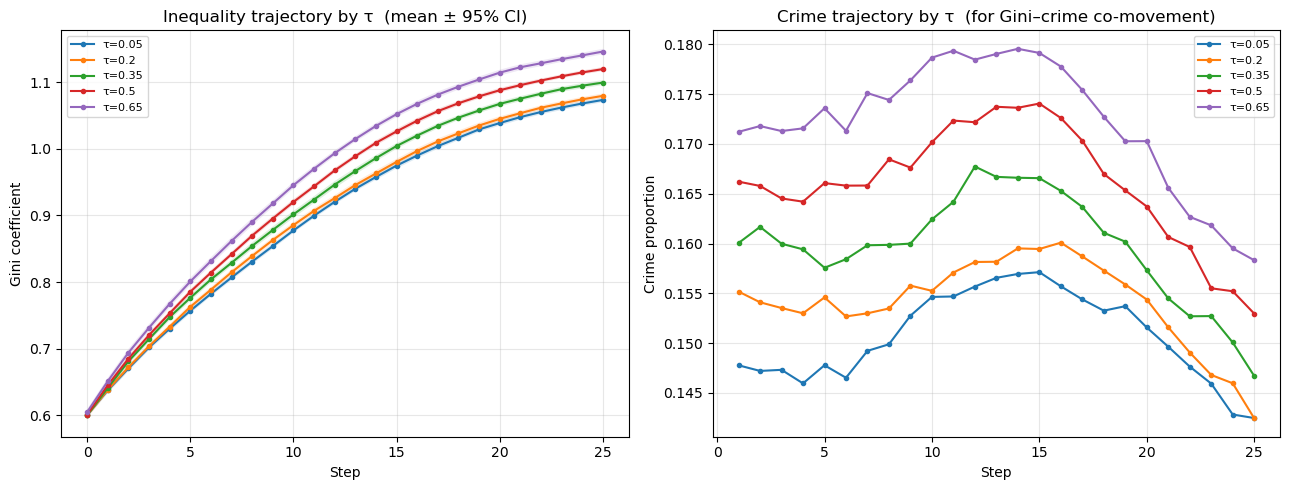

In [9]:
agg = (df.groupby(["tau", "step"])
         .agg(gini_mean=("gini", "mean"), gini_sd=("gini", "std"),
              crime_mean=("crime", "mean"))
         .reset_index())
ci = 1.96 / np.sqrt(N_REPS)        # half-width multiplier for the 95% CI band

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for tau in TAU_VALUES:
    s = agg[agg.tau == tau]
    ax1.plot(s.step, s.gini_mean, marker="o", ms=3, label=f"τ={tau}")
    ax1.fill_between(s.step, s.gini_mean - ci * s.gini_sd,
                     s.gini_mean + ci * s.gini_sd, alpha=0.15)
ax1.set(xlabel="Step", ylabel="Gini coefficient",
        title="Inequality trajectory by τ  (mean ± 95% CI)")
ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

for tau in TAU_VALUES:
    s = agg[agg.tau == tau]
    ax2.plot(s.step, s.crime_mean, marker="o", ms=3, label=f"τ={tau}")
ax2.set(xlabel="Step", ylabel="Crime proportion",
        title="Crime trajectory by τ  (for Gini–crime co-movement)")
ax2.legend(fontsize=8); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [10]:
def stabilization_step(g, tol=0.005):
    # First step after which |delta Gini| stays below tol for the rest of the run.
    d = np.abs(np.diff(g))
    for i in range(len(d)):
        if np.all(d[i:] < tol):
            return i + 1
    return np.nan

rows = []
for tau in TAU_VALUES:
    g = agg[agg.tau == tau].sort_values("step")["gini_mean"].values
    rows.append(dict(tau=tau,
                     gini_step0=g[0],
                     gini_final=g[-1],
                     delta=g[-1] - g[0],
                     within_run_range=g.max() - g.min(),
                     stabilizes_at_step=stabilization_step(g)))
summ = pd.DataFrame(rows).round(4)

final_spread = summ["gini_final"].max() - summ["gini_final"].min()
print(summ.to_string(index=False))
print(f"\nCross-τ spread in FINAL Gini : {final_spread:.4f}")
print(f"Largest |Δ| over a run        : {summ['delta'].abs().max():.4f}")

 tau  gini_step0  gini_final  delta  within_run_range  stabilizes_at_step
0.05      0.6005      1.0733 0.4727            0.4727                 NaN
0.20      0.6002      1.0794 0.4791            0.4791                 NaN
0.35      0.6003      1.0993 0.4990            0.4990                25.0
0.50      0.6012      1.1195 0.5183            0.5183                25.0
0.65      0.6050      1.1458 0.5408            0.5408                 NaN

Cross-τ spread in FINAL Gini : 0.0725
Largest |Δ| over a run        : 0.5408


## How to read this — the λ-calibration decision

Two sources of identifying variation; you need at least one to be non-trivial:

- **Temporal** (within a run): look at `delta` and `within_run_range`, and the left panel. If Gini is essentially flat from step 0 across every τ (large `gini_step0`, near-zero `delta`, `stabilizes_at_step` ≈ 1), inequality is **saturated at initialization** — your Pareto start plus the −250 penalty tail fix it immediately, and a *temporal* crime–inequality calibration has nothing to grip.
- **Cross-condition**: `Cross-τ spread in FINAL Gini`. If temporal variation is weak but the cross-τ spread is sizeable, calibrate λ off the **cross-condition** crime–inequality relationship instead, and say so explicitly.

If *both* are small, you don't have identification for a magnitude — anchor λ by a neutral convention (e.g. λ = 1) and present the inequality–crime relationship as a qualitative prediction (sign + shape) rather than a calibrated degree.

Reminder: this is the **current** mechanism. After you implement the reference-shift deprivation, re-run with `FAST_PREVIEW=False` — and ideally repeat at β ∈ {−1, 0, +1}, since β is your dominant crime modulator and moves the penalty-driven wealth dynamics that generate the Gini.